# Task 4: Augmentation module sanity checks
Verifies stratified_mixup before it is used inside LOPO CV folds:
correct synthetic counts, correct weights, categorical coherence,
and that synthetic rows live inside the real data manifold.
The real per-fold augmentation calls happen in the training notebook.

In [1]:
# load dataset & setup
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, joblib

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.utils.augmentation import stratified_mixup

df = pd.read_csv(PROJECT_ROOT / "data/processed/merged_rice_yield_dataset.csv")
df["temp_mean_c"] = (df["temp_max_c"] + df["temp_min_c"]) / 2
df["temp_range_c"] = df["temp_max_c"] - df["temp_min_c"]

split_info = json.load(open(PROJECT_ROOT / "artifacts/split_provinces.json"))
df_train = df[df["province"].isin(split_info["train_provinces"])].copy()

X_train_raw = df_train.drop(columns=["yield_mt_ha", "province"])
y_train = df_train["yield_mt_ha"].to_numpy()

preprocessor = joblib.load(PROJECT_ROOT / "models/preprocessing_pipeline.joblib")
X_train_proc = preprocessor.transform(X_train_raw)

strata = (df_train["season_period"] + "|" + df_train["ecosystem"]
          + "|" + df_train["island_group"]).to_numpy()

print("Processed train shape:", X_train_proc.shape)
print("\nStratum sizes:")
print(pd.Series(strata).value_counts())

Processed train shape: (229, 15)

Stratum sizes:
2021_Semester_2|Irrigated|Luzon           29
2022_Semester_1|Irrigated|Luzon           29
2021_Semester_2|Non-irrigated|Luzon       28
2022_Semester_1|Non-irrigated|Luzon       21
2021_Semester_2|Irrigated|Mindanao        18
2021_Semester_2|Non-irrigated|Mindanao    18
2022_Semester_1|Irrigated|Mindanao        18
2022_Semester_1|Non-irrigated|Mindanao    18
2021_Semester_2|Irrigated|Visayas         13
2022_Semester_1|Irrigated|Visayas         13
2021_Semester_2|Non-irrigated|Visayas     12
2022_Semester_1|Non-irrigated|Visayas     12
Name: count, dtype: int64


In [2]:
# mixup and check results: unit test
MULTIPLIER = 2
SEED = 42

X_aug, y_aug, w_aug = stratified_mixup(
    X_train_proc, y_train, strata,
    multiplier=MULTIPLIER, random_state=SEED,
)

n_real = len(y_train)
print(f"Real: {n_real} | Synthetic: {len(y_aug) - n_real} | Total: {len(y_aug)}")
print(f"Weight 1.0 rows: {(w_aug == 1.0).sum()} | Weight 0.5 rows: {(w_aug == 0.5).sum()}")
print(f"Synthetic yield range: [{y_aug[n_real:].min():.2f}, {y_aug[n_real:].max():.2f}]")
print(f"Real yield range:      [{y_train.min():.2f}, {y_train.max():.2f}]")

Real: 229 | Synthetic: 229 | Total: 458
Weight 1.0 rows: 229 | Weight 0.5 rows: 229
Synthetic yield range: [1.37, 6.74]
Real yield range:      [1.22, 6.77]


In [3]:
# categorical coherence check
feature_names = json.load(open(PROJECT_ROOT / "artifacts/feature_order.json"))
cat_idx = [i for i, nm in enumerate(feature_names) if nm.startswith("cat__")]

real_patterns = {tuple(r) for r in X_train_proc[:, cat_idx].round(6)}
synth_patterns = {tuple(r) for r in X_aug[n_real:, cat_idx].round(6)}

print("Unique dummy patterns in real rows:", len(real_patterns))
print("Impossible synthetic patterns:", len(synth_patterns - real_patterns))

Unique dummy patterns in real rows: 12
Impossible synthetic patterns: 0


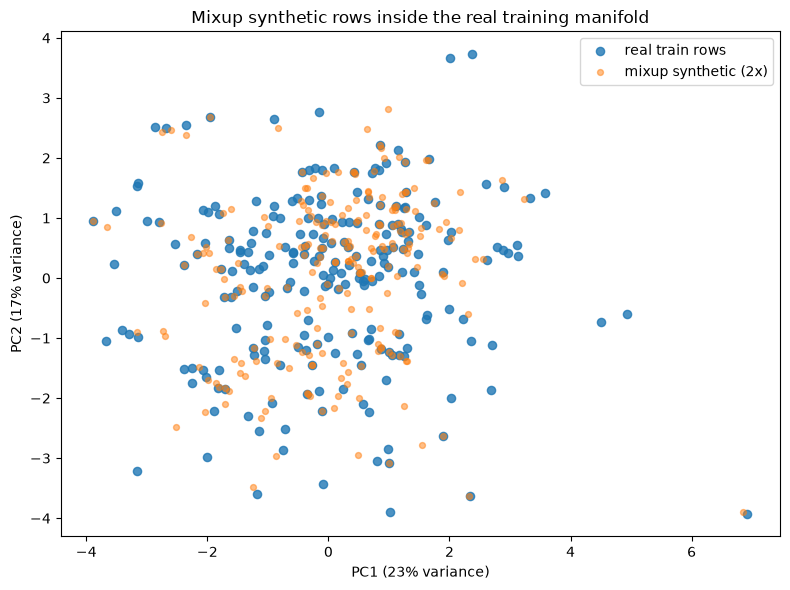

In [4]:
# pca figure
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
Z_real = pca.fit_transform(X_train_proc)      # PCA learns from REAL rows only
Z_synth = pca.transform(X_aug[n_real:])       # synthetic rows merely projected

plt.figure(figsize=(8, 6))
plt.scatter(Z_real[:, 0], Z_real[:, 1], s=35, alpha=0.8, label="real train rows")
plt.scatter(Z_synth[:, 0], Z_synth[:, 1], s=18, alpha=0.5, label="mixup synthetic (2x)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
plt.title("Mixup synthetic rows inside the real training manifold")
plt.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "docs/figures/mixup_pca_check.png", dpi=300)
plt.show()

## Task 4 Summary: Stratified Mixup Augmentation (module + verification)

### Method
- Implementation: `src/models/utils/augmentation.py::stratified_mixup`
  (single source of truth, imported by all notebooks).
- Mixup blends two real rows and their yields at ratio λ ~ Beta(0.4, 0.4);
  the same λ is used for features and target.
- Stratified: pairs are drawn only within the same
  (season_period, ecosystem, island_group) stratum, so synthetic rows
  always keep a valid category combination.
- Multiplier convention: multiplier m creates (m − 1)·n synthetic rows;
  m = 1 is the no-augmentation control. Multipliers tested: 1, 2, 3, 5.
- Sample weights: real rows 1.0, synthetic rows 0.5.
- Leakage rule: augmentation is applied **inside each LOPO CV fold**, on that
  fold's training rows only. The held-out test set is never augmented.

### Verification on the full training split (229 rows, 12 strata)
- 2x run produced 229 synthetic rows; weight split 229 @ 1.0 / 229 @ 0.5.
- Synthetic yield range [1.37, 6.74] lies strictly inside the real range
  [1.22, 6.77]: convex blends interpolate and cannot extrapolate.
- Impossible categorical dummy patterns: 0 (stratification held).
- PCA projection fitted on real rows only shows the synthetic cloud inside
  the real manifold (docs/figures/mixup_pca_check.png). PC1+PC2 explain
  ~40% of variance, so the figure is illustrative; the numeric checks
  above are the formal evidence.

### Decisions logged
- Stratified pairing chosen over unrestricted pairing so synthetic farms
  remain agronomically coherent (no "half-irrigated" rows).
- Module-based implementation chosen over notebook copy-paste so the
  augmentation logic cannot drift between notebooks.